# Part 5 — Development and Model Selection

**BFT65B — Big Data Analytics in Finance | Student ID: 11230945**

Compare predefined models using purged chronological development folds. Set an event-level economic alarm threshold from out-of-fold predictions, demonstrate Spark MLlib and seal the final development estimators. No historical test is scored in this notebook.

## 1. Repository and runtime
Use a fresh CPU runtime, Java 17 or later, and the pinned dependencies. Use the same Python and dependency versions for both Part 5 notebooks.

In [ ]:
from pathlib import Path
import os, sys, subprocess, json, shutil
REPO_URL = "https://github.com/NguyenDuong0508/11230945.git"
REPO = Path("/content/11230945")
if not REPO.exists():
    subprocess.run(["git", "clone", REPO_URL, str(REPO)], check=True)
else:
    assert subprocess.check_output(["git", "remote", "get-url", "origin"], cwd=REPO, text=True).strip() == REPO_URL
    subprocess.run(["git", "pull", "--ff-only"], cwd=REPO, check=True)
print("Git revision:", subprocess.check_output(["git", "rev-parse", "HEAD"], cwd=REPO, text=True).strip())
java = shutil.which("java")
if java is None:
    raise RuntimeError("Java 17 or later is required")
os.environ["JAVA_HOME"] = str(Path(java).resolve().parents[1])
os.environ["SPARK_LOCAL_IP"] = "127.0.0.1"
os.environ["PYSPARK_PYTHON"] = sys.executable
print(subprocess.run([java,"-version"],check=True,capture_output=True,text=True).stderr)
subprocess.run([sys.executable,"-m","pip","install","-r",str(REPO/"requirements.txt")],check=True)
sys.path.insert(0,str(REPO/'src'))
def command(action):
    proc = subprocess.Popen([sys.executable,str(REPO/'run_part5.py'),action,'--workspace',str(WORKSPACE)],cwd=REPO,stdout=subprocess.PIPE,stderr=subprocess.STDOUT,text=True,bufsize=1)
    for line in proc.stdout:
        print(line,end='',flush=True)
    if proc.wait()!=0:
        raise RuntimeError(f'Part 5 {action} failed; inspect diagnostics')

Git revision: e74142601962bf6646798e5564eb9d4ab56c271a
openjdk version "21.0.12.1" 2026-08-18
OpenJDK Runtime Environment (build 21.0.12.1+1-1-24.04.4-Ubuntu)
OpenJDK 64-Bit Server VM (build 21.0.12.1+1-1-24.04.4-Ubuntu, mixed mode, sharing)



## 2. Mandatory offline validation
Run the complete test suite, including real Parquet and Spark integration. A failed or skipped test stops the pipeline.

In [ ]:
import xml.etree.ElementTree as ET
TESTS_PASSED = False
result_path = Path('/content/part5_tests.xml')
result_path.unlink(missing_ok=True)
result = subprocess.run([sys.executable,'-m','pytest','-q','-ra','--tb=short','--show-capture=no',f'--junitxml={result_path}','tests'],cwd=REPO,env=dict(os.environ,PYTEST_DISABLE_PLUGIN_AUTOLOAD='1',SPARK_LOCAL_IP='127.0.0.1',PYSPARK_PYTHON=sys.executable,MPLBACKEND='Agg'),capture_output=True,text=True)
print(result.stdout)
if result.stderr: print(result.stderr)
if not result_path.is_file(): raise RuntimeError('Missing pytest report')
cases=list(ET.parse(result_path).getroot().iter('testcase'))
problems=[(case,node) for case in cases for node in case if node.tag in ('failure','error','skipped')]
for case,node in problems:
    print(case.get('classname'),case.get('name'),node.tag,node.get('message'),node.text or '')
if result.returncode or not cases or problems: raise RuntimeError('Offline validation failed; inspect diagnostics')
TESTS_PASSED=True
print(f'Mandatory offline validation: PASS ({len(cases)} tests, zero skips)')

........................................................................ [ 54%]
............................................................             [100%]
----------------- generated xml file: /content/part5_tests.xml -----------------
132 passed in 314.36s (0:05:14)

Mandatory offline validation: PASS (132 tests, zero skips)


## 3. Verified upstream identities
Check the sealed Gold and Silver inventories and Bronze manifest identity. Development does not decode the historical test partitions.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')
WORKSPACE=Path('/content/drive/MyDrive/11230945')
assert TESTS_PASSED
from fdic_ews.modelling.pipeline import upstream, evidence_path, verify_development, verify_oof
from fdic_ews.contracts import sha256
GOLD, gm, SILVER, IDENTITY = upstream(WORKSPACE)
EVIDENCE=evidence_path(WORKSPACE,IDENTITY)
ATTEMPT=EVIDENCE.parent/'test_attempt.json'
print('Verified upstream identities:',json.dumps(IDENTITY,indent=2))
print('Gold decision quarters:',gm['summary']['decision_quarters'])
print('Gold predictors:',gm['summary']['feature_count'])
print('Represented test-calendar failures:',gm['summary']['test_distinct_failure_certs_in_calendar_period'])
print('Evidence directory:',EVIDENCE)

Mounted at /content/drive
Verified upstream identities: {
  "gold": "de2abf748e29025760f50cc6c3c57d899a4402fe079756e17f9a6d93f21b5780",
  "silver": "b6d91c7d0095b81e6200a0ae0940a103968c452046b168e446cd02089d323af0",
  "bronze": "e376152baac058e4dd4fff4582e9afa3c58820fff2f278115a82bff7fd4b3f6e"
}
Gold decision quarters: 166
Gold predictors: 29
Represented test-calendar failures: 505
Evidence directory: /content/drive/MyDrive/11230945/modelling/de2abf748e29025760f50cc6c3c57d899a4402fe079756e17f9a6d93f21b5780


## 4. Fixed chronological design and candidate specifications
The late validation block is sparse in failures. Four validation blocks cover distinct historical regimes. Every fold has a four-quarter gap between its training end and validation start; model fitting and threshold estimation use development only.

In [ ]:
import pandas as pd
import numpy as np
from IPython.display import display
from fdic_ews.modelling.design import FOLDS,SPECS,validate_design
validate_design()
display(pd.DataFrame([{'fold':f.name,'training_end':f.train_end,'validation_start':f.start,'validation_end':f.end} for f in FOLDS]))
display(pd.DataFrame([{'specification':name,'estimator':kind,'raw_predictors':len(features),'capital_zero_as_missing':mask} for name,(kind,features,mask) in SPECS.items()]))

,fold,training_end,validation_start,validation_end
0,F1,1987-12-31,1989-03-31,1992-12-31
1,F2,1992-12-31,1994-03-31,1997-12-31
2,F3,1997-12-31,1999-03-31,2000-12-31
3,F4,2000-12-31,2002-03-31,2006-12-31


,specification,estimator,raw_predictors,capital_zero_as_missing
0,prior,prior,29,False
1,logistic,logistic,29,False
2,hist_gradient,hist_gradient,29,False
3,lightgbm_full,lightgbm,29,False
4,lightgbm_core,lightgbm,21,False
5,lightgbm_no_peer,lightgbm,28,False
6,lightgbm_no_quality,lightgbm,22,False
7,lightgbm_zero_missing,lightgbm,29,True


## 5. Execute development and seal the choices
The initial run performs all 32 fold fits, development-only threshold optimization, the native Spark demonstration and two final development refits. An existing sealed run is inspected without refitting. An incomplete run must be diagnosed; do not overwrite a sealed run.

In [ ]:
if (EVIDENCE/'development_manifest.json').is_file():
    print('Existing development seal: read-only verification.')
else:
    if ATTEMPT.exists(): raise RuntimeError('Historical test already attempted; development is closed')
    command('develop')
DM=verify_development(EVIDENCE,IDENTITY)
verify_oof(EVIDENCE,DM)
S=DM['summary']
SELECTED=S['selected_model']
print('Development state:',DM['state'])
print('Selection:',SELECTED)
print('Seal SHA-256:',sha256(EVIDENCE/'development_manifest.json'))
print('Historical test scored: no (this notebook)')

F1 prior: AP=0.016548
F1 logistic: AP=0.362873
F1 hist_gradient: AP=0.360990
F1 lightgbm_full: AP=0.405031
F1 lightgbm_core: AP=0.360144
F1 lightgbm_no_peer: AP=0.392576
F1 lightgbm_no_quality: AP=0.371453
F1 lightgbm_zero_missing: AP=0.390486
F2 prior: AP=0.000514
F2 logistic: AP=0.190948
F2 hist_gradient: AP=0.232941
F2 lightgbm_full: AP=0.231012
F2 lightgbm_core: AP=0.219137
F2 lightgbm_no_peer: AP=0.245790
F2 lightgbm_no_quality: AP=0.245155
F2 lightgbm_zero_missing: AP=0.210873
F3 prior: AP=0.000656
F3 logistic: AP=0.114362
F3 hist_gradient: AP=0.223666
F3 lightgbm_full: AP=0.210230
F3 lightgbm_core: AP=0.202992
F3 lightgbm_no_peer: AP=0.196996
F3 lightgbm_no_quality: AP=0.226945
F3 lightgbm_zero_missing: AP=0.199252
F4 prior: AP=0.000255
F4 logistic: AP=0.021935
F4 hist_gradient: AP=0.013041
F4 lightgbm_full: AP=0.018275
F4 lightgbm_core: AP=0.025254
F4 lightgbm_no_peer: AP=0.018860
F4 lightgbm_no_quality: AP=0.023560
F4 lightgbm_zero_missing: AP=0.023965
[0.001s][warning][os,con

## 6. Chronological validation results
Average precision is the primary selection measure. Report fold-specific prevalence, AP, ROC-AUC and Brier score. Equal-weight fold averages are used for selection; pooled OOF metrics are complementary because score scales can vary across folds.

**Table 1. Chronological fold populations**

Fold,Training end,Validation start,Validation end,Training rows,Training positives,Validation rows,Validation positives,Failure events,Prevalence
F1,1987-12-31,1989-03-31,1992-12-31,"258,180","2,536","233,498","3,864","1,090",1.6548%
F2,1992-12-31,1994-03-31,1997-12-31,"555,746","7,458","180,852",93,33,0.0514%
F3,1997-12-31,1999-03-31,2000-12-31,"788,194","7,646","77,743",51,17,0.0656%
F4,2000-12-31,2002-03-31,2006-12-31,"906,299","7,718","176,285",45,15,0.0255%


**Table 2. Fold-level average precision**

Model,F1,F2,F3,F4
LightGBM (No Quality),0.371453,0.245155,0.226945,0.023560
LightGBM (Full),0.405031,0.231012,0.210230,0.018275
LightGBM (No Peer),0.392576,0.245790,0.196996,0.018860
Histogram Gradient Boosting,0.360990,0.232941,0.223666,0.013041
LightGBM (Zero Missing),0.390486,0.210873,0.199252,0.023965
LightGBM (Core),0.360144,0.219137,0.202992,0.025254
Logistic Regression,0.362873,0.190948,0.114362,0.021935
Prior Baseline,0.016548,0.000514,0.000656,0.000255


**Table 3. Chronological model comparison**

Model,Mean AP,Mean ROC-AUC,Mean Brier score,Median fit time (s),F1–F3 mean AP,F4 AP,Selected
LightGBM (No Quality),0.216778,0.912264,0.003579,18.69,0.281185,0.023560,Yes
LightGBM (Full),0.216137,0.917694,0.003471,21.36,0.282091,0.018275,No
LightGBM (No Peer),0.213555,0.915902,0.003465,20.44,0.278454,0.018860,No
Histogram Gradient Boosting,0.207659,0.910935,0.003597,27.76,0.272532,0.013041,No
LightGBM (Zero Missing),0.206144,0.920698,0.003438,22.03,0.266870,0.023965,No
LightGBM (Core),0.201882,0.919579,0.003607,16.57,0.260758,0.025254,No
Logistic Regression,0.172530,0.883830,0.003789,22.91,0.222728,0.021935,No
Prior Baseline,0.004493,0.500000,0.004515,0.07,0.005906,0.000255,No


**Table 4. Pooled out-of-fold ranking diagnostics**

Model,Observations,Positives,Prevalence,AP,ROC-AUC,Brier score,Log loss,Top-5% recall
LightGBM (No Quality),"668,378","4,053",0.6064%,0.344170,0.969608,0.004804,0.020521,67.53%
LightGBM (Full),"668,378","4,053",0.6064%,0.374200,0.970514,0.004649,0.019950,67.75%
LightGBM (No Peer),"668,378","4,053",0.6064%,0.367428,0.968534,0.004640,0.019944,67.38%
Histogram Gradient Boosting,"668,378","4,053",0.6064%,0.336256,0.967876,0.004822,0.021217,64.42%
LightGBM (Zero Missing),"668,378","4,053",0.6064%,0.367646,0.969182,0.004603,0.019821,68.27%
LightGBM (Core),"668,378","4,053",0.6064%,0.330311,0.967265,0.004840,0.020810,65.61%
Logistic Regression,"668,378","4,053",0.6064%,0.283796,0.847136,0.005058,0.026527,66.30%
Prior Baseline,"668,378","4,053",0.6064%,0.009286,0.554560,0.006057,0.038435,0.67%


**Selected specification:** LightGBM (No Quality)

*Note: Model selection is based on equal-weight mean fold AP. Pooled OOF metrics provide complementary diagnostics and do not determine model selection.*

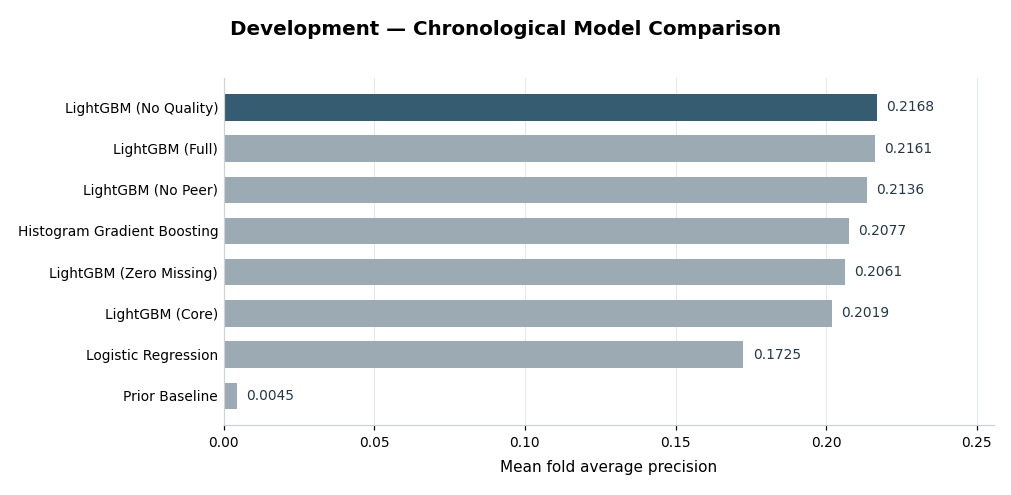

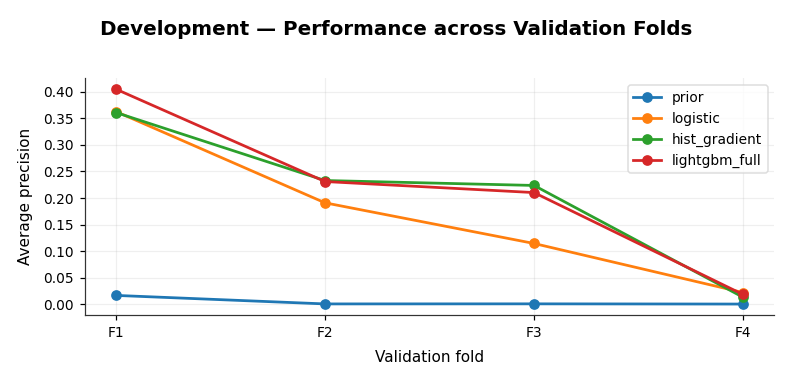

*Note: The figure compares the prior baseline, Logistic Regression, Histogram Gradient Boosting and full LightGBM across four chronological validation folds. All eight specifications are reported in Tables 2 and 3.*

In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

from io import BytesIO
from IPython.display import display, Markdown, HTML, Image


# ============================================================
# Presentation settings
# ============================================================

PRIMARY = "#365C72"
SECONDARY = "#9CAAB4"
ACCENT = "#B58B59"
GRID = "#E2E6EA"
TEXT = "#243746"

MODEL_LABELS = {
    "prior": "Prior Baseline",
    "logistic": "Logistic Regression",
    "hist_gradient": "Histogram Gradient Boosting",
    "lightgbm_full": "LightGBM (Full)",
    "lightgbm_core": "LightGBM (Core)",
    "lightgbm_no_peer": "LightGBM (No Peer)",
    "lightgbm_no_quality": "LightGBM (No Quality)",
    "lightgbm_zero_missing": "LightGBM (Zero Missing)"
}

MODEL_COLORS = {
    "prior": "#9CAAB4",
    "logistic": "#7895A5",
    "hist_gradient": "#B58B59",
    "lightgbm_full": "#789B91",
    SELECTED: PRIMARY
}

SCENARIO_LABELS = {
    "review_half": "Review cost × 0.5",
    "primary": "Primary scenario",
    "review_double": "Review cost × 2",
    "miss_half": "Missed-event cost × 0.5",
    "miss_double": "Missed-event cost × 2"
}

plt.rcParams.update({
    "figure.dpi": 110,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "font.family": "DejaVu Sans",
    "font.size": 10,
    "axes.titlesize": 11,
    "axes.titleweight": "bold",
    "axes.titlepad": 12,
    "axes.labelsize": 10,
    "axes.labelpad": 7,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#CBD2D8",
    "legend.fontsize": 8,
    "legend.frameon": False,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9
})


# ============================================================
# Shared formatting functions
# ============================================================

def spacer(height=28):
    """Insert vertical spacing between notebook outputs."""

    display(HTML(
        f'<div style="height:{height}px;'
        f'min-height:{height}px;'
        'line-height:0;">&nbsp;</div>'
    ))


def display_table(df, title, labels=None, formats=None):
    """Render a formatted table without modifying evidence."""

    table = df.copy()

    if "model" in table.columns:
        table["model"] = table["model"].replace(MODEL_LABELS)

    if "specification" in table.columns:
        table["specification"] = (
            table["specification"].replace(MODEL_LABELS)
        )

    if "scenario" in table.columns:
        table["scenario"] = (
            table["scenario"].replace(SCENARIO_LABELS)
        )

    spacer(28)

    display(Markdown(f"**{title}**"))

    styler = (
        table.style
        .format(formats or {}, na_rep="—")
        .hide(axis="index")
        .set_table_styles([
            {
                "selector": "th",
                "props": [
                    ("background-color", PRIMARY),
                    ("color", "white"),
                    ("font-weight", "600"),
                    ("font-size", "11px"),
                    ("padding", "9px 12px"),
                    ("text-align", "center"),
                    ("white-space", "normal")
                ]
            },
            {
                "selector": "td",
                "props": [
                    ("font-size", "11px"),
                    ("padding", "8px 12px"),
                    ("color", TEXT),
                    ("border-bottom", "1px solid #E2E6EA")
                ]
            },
            {
                "selector": "tbody tr:nth-child(odd)",
                "props": [
                    ("background-color", "#F2F5F7")
                ]
            },
            {
                "selector": "tbody tr:nth-child(even)",
                "props": [
                    ("background-color", "#FFFFFF")
                ]
            }
        ])
        .relabel_index(
            [labels.get(c, c) for c in table.columns]
            if labels else list(table.columns),
            axis="columns"
        )
    )

    display(styler)


def show_figure(fig, title, width=900):
    """Display a compact figure with consistent spacing."""

    fig.suptitle(
        title,
        fontsize=13,
        fontweight="bold"
    )

    fig.get_layout_engine().set(
        h_pad=0.18,
        w_pad=0.16,
        hspace=0.15,
        wspace=0.12
    )

    buffer = BytesIO()

    fig.savefig(
        buffer,
        format="png",
        dpi=110,
        facecolor="white"
    )

    plt.close(fig)

    spacer(32)

    display(Image(
        data=buffer.getvalue(),
        width=width
    ))

    buffer.close()

    spacer(24)


# ============================================================
# Load verified development evidence
# ============================================================

fold_counts = pd.read_csv(
    EVIDENCE / "fold_counts.csv"
)

fold_metrics = pd.read_csv(
    EVIDENCE / "fold_metrics.csv"
)

comparison = pd.read_csv(
    EVIDENCE / "model_comparison.csv"
)

pooled = pd.read_csv(
    EVIDENCE / "pooled_metrics.csv"
)

model_order = comparison.sort_values(
    "mean_ap",
    ascending=False
).model.tolist()


# ============================================================
# Table 1. Chronological fold populations
# ============================================================

fold_display = fold_counts.copy()

fold_display["validation_prevalence"] = (
    fold_display["validation_positive"]
    / fold_display["validation_rows"]
)

display_table(
    fold_display,
    "Table 1. Chronological fold populations",
    labels={
        "fold": "Fold",
        "train_end": "Training end",
        "validation_start": "Validation start",
        "validation_end": "Validation end",
        "train_rows": "Training rows",
        "train_positive": "Training positives",
        "validation_rows": "Validation rows",
        "validation_positive": "Validation positives",
        "validation_events": "Failure events",
        "validation_prevalence": "Prevalence"
    },
    formats={
        **{
            c: "{:,.0f}"
            for c in [
                "train_rows",
                "train_positive",
                "validation_rows",
                "validation_positive",
                "validation_events"
            ]
        },
        "validation_prevalence": "{:.4%}"
    }
)


# ============================================================
# Table 2. Fold-level average precision
# ============================================================

ap_table = (
    fold_metrics
    .pivot(
        index="model",
        columns="fold",
        values="ap"
    )
    .reindex(model_order)
    .reset_index()
)

ap_table.columns.name = None

display_table(
    ap_table,
    "Table 2. Fold-level average precision",
    labels={"model": "Model"},
    formats={
        c: "{:.6f}"
        for c in ap_table.columns
        if c != "model"
    }
)


# ============================================================
# Table 3. Model comparison
# ============================================================

display_table(
    comparison,
    "Table 3. Chronological model comparison",
    labels={
        "model": "Model",
        "mean_ap": "Mean AP",
        "mean_roc_auc": "Mean ROC-AUC",
        "mean_brier": "Mean Brier score",
        "median_fit_seconds": "Median fit time (s)",
        "early_folds_mean_ap": "F1–F3 mean AP",
        "late_fold_ap": "F4 AP",
        "selected": "Selected"
    },
    formats={
        "mean_ap": "{:.6f}",
        "mean_roc_auc": "{:.6f}",
        "mean_brier": "{:.6f}",
        "median_fit_seconds": "{:,.2f}",
        "early_folds_mean_ap": "{:.6f}",
        "late_fold_ap": "{:.6f}",
        "selected": lambda x: "Yes" if x else "No"
    }
)


# ============================================================
# Table 4. Pooled out-of-fold diagnostics
# ============================================================

pooled_display = (
    pooled.set_index("model")
    .reindex(model_order)
    .reset_index()
)

display_table(
    pooled_display,
    "Table 4. Pooled out-of-fold ranking diagnostics",
    labels={
        "model": "Model",
        "rows": "Observations",
        "positives": "Positives",
        "prevalence": "Prevalence",
        "ap": "AP",
        "roc_auc": "ROC-AUC",
        "brier": "Brier score",
        "log_loss": "Log loss",
        "recall_top5pct_by_quarter": "Top-5% recall"
    },
    formats={
        "rows": "{:,.0f}",
        "positives": "{:,.0f}",
        "prevalence": "{:.4%}",
        "ap": "{:.6f}",
        "roc_auc": "{:.6f}",
        "brier": "{:.6f}",
        "log_loss": "{:.6f}",
        "recall_top5pct_by_quarter": "{:.2%}"
    }
)

spacer(12)

display(Markdown(
    f"**Selected specification:** "
    f"{MODEL_LABELS.get(SELECTED, SELECTED)}"
))

display(Markdown(
    "*Note: Model selection is based on equal-weight "
    "mean fold AP. Pooled OOF metrics provide complementary "
    "diagnostics and do not determine model selection.*"
))


# ============================================================
# Figure 1. Model comparison
# ============================================================

ordered = comparison.sort_values(
    "mean_ap",
    ascending=True
)

fig, ax = plt.subplots(
    figsize=(9.2, 4.5),
    layout="constrained"
)

bars = ax.barh(
    ordered.model.map(MODEL_LABELS),
    ordered.mean_ap,
    color=[
        PRIMARY if name == SELECTED else SECONDARY
        for name in ordered.model
    ],
    height=0.64
)

ax.bar_label(
    bars,
    fmt="%.4f",
    padding=6,
    fontsize=9,
    color=TEXT
)

ax.set(
    xlabel="Mean fold average precision",
    xlim=(0, ordered.mean_ap.max() * 1.18)
)

ax.xaxis.set_major_formatter(
    mtick.FormatStrFormatter("%.2f")
)

ax.grid(
    axis="x",
    color=GRID,
    linewidth=0.6
)

ax.set_axisbelow(True)
ax.tick_params(axis="y", length=0)

show_figure(
    fig,
    "Development — Chronological Model Comparison",
    width=850
)



# ============================================================
# Figure 2. Performance across validation folds
# ============================================================

pivot = fold_metrics.pivot(
    index="fold",
    columns="model",
    values="ap"
).reindex(["F1", "F2", "F3", "F4"])

plot_models = [
    "prior",
    "logistic",
    "hist_gradient",
    "lightgbm_full"
]

plot_colors = {
    "prior": "#1f77b4",
    "logistic": "#ff7f0e",
    "hist_gradient": "#2ca02c",
    "lightgbm_full": "#d62728"
}

fig, ax = plt.subplots(
    figsize=(7.2, 3.5),
    layout="constrained"
)

for name in plot_models:
    ax.plot(
        pivot.index,
        pivot[name],
        color=plot_colors[name],
        marker="o",
        markersize=6,
        linewidth=1.8,
        label=name
    )

ax.set(
    xlabel="Validation fold",
    ylabel="Average precision"
)

ax.set_ylim(
    -0.02,
    pivot[plot_models].max().max() * 1.05
)

ax.yaxis.set_major_locator(
    mtick.MultipleLocator(0.05)
)

ax.yaxis.set_major_formatter(
    mtick.FormatStrFormatter("%.2f")
)

ax.spines["left"].set_color("#333333")
ax.spines["bottom"].set_color("#333333")

ax.grid(
    True,
    alpha=0.2,
    linewidth=0.8
)

ax.set_axisbelow(True)

ax.legend(
    loc="upper right",
    fontsize=9,
    frameon=True,
    facecolor="white",
    edgecolor="#D5D5D5"
)

show_figure(
    fig,
    "Development — Performance across Validation Folds",
    width=850
)

display(Markdown(
    "*Note: The figure compares the prior baseline, "
    "Logistic Regression, Histogram Gradient Boosting "
    "and full LightGBM across four chronological "
    "validation folds. All eight specifications are "
    "reported in Tables 2 and 3.*"
))

spacer(20)


## 7. Feature contribution and capital-zero sensitivity
Compare full LightGBM with fixed feature ablations and an alternative zero treatment under identical model settings. These are development comparisons, not test-informed feature selection. Training-fit importance, if available, is descriptive.

**Table 5. Controlled LightGBM specifications**

Specification,Mean AP,F1–F3 mean AP,F4 AP,Δ AP vs. full
LightGBM (No Quality),0.216778,0.281185,0.023560,+0.000641
LightGBM (Full),0.216137,0.282091,0.018275,+0.000000
LightGBM (No Peer),0.213555,0.278454,0.018860,-0.002582
LightGBM (Zero Missing),0.206144,0.266870,0.023965,-0.009993
LightGBM (Core),0.201882,0.260758,0.025254,-0.014255


**Supplementary table. Selected-model training-fit importance**

Predictor,Importance,Importance measure
Return on equity,"119,764.59",training_gain
Return on assets,"95,251.98",training_gain
Texas-like Ratio,"94,388.45",training_gain
Equity / Assets,"80,343.78",training_gain
Reported RBC1AAJ,"44,504.99",training_gain
Reported RBCRWAJ,"22,896.74",training_gain
Tangible equity / Assets,"12,938.30",training_gain
Brokered deposits missingness,"11,462.30",training_gain
Annual asset growth,"7,716.00",training_gain
Securities / Assets,"7,296.13",training_gain


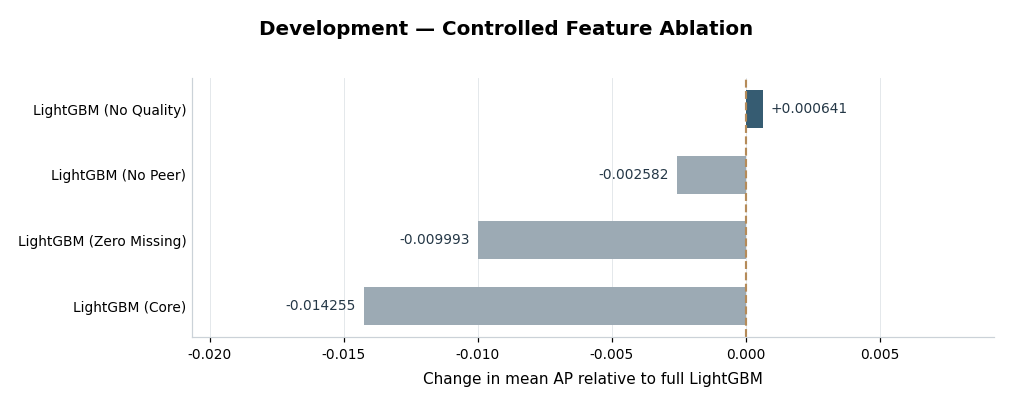

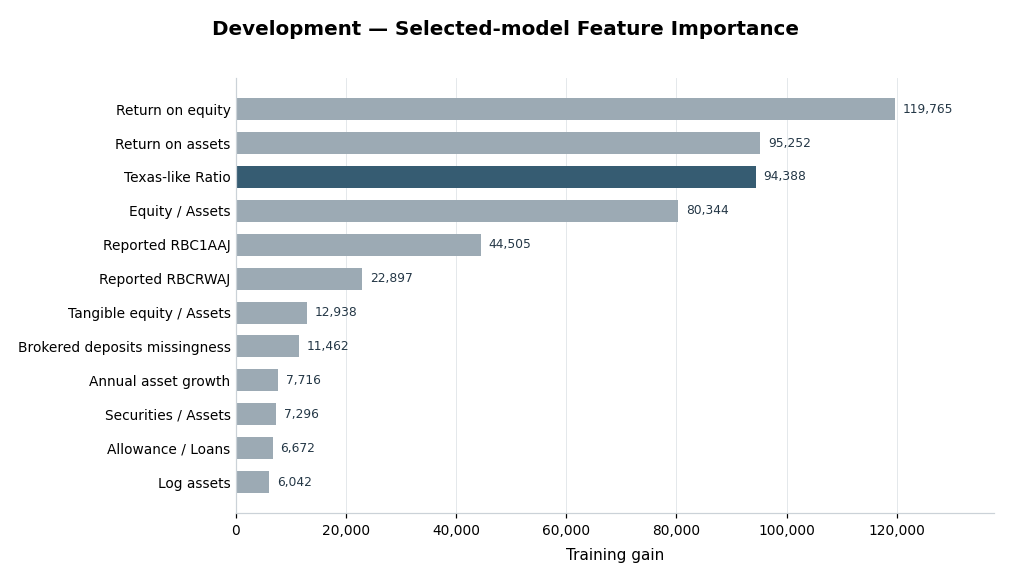

*Note: Ablation results are based on chronological development folds. Native feature importance is descriptive of the fitted development model and does not establish causality or independent predictive contribution.*

In [ ]:

# ============================================================
# Table 5. Controlled LightGBM specifications
# ============================================================

ablation = comparison.loc[
    comparison.model.str.startswith("lightgbm")
].copy()

full = float(
    ablation.loc[
        ablation.model.eq("lightgbm_full"),
        "mean_ap"
    ].iloc[0]
)

ablation["delta_ap_vs_full"] = (
    ablation.mean_ap - full
)

display_table(
    ablation[[
        "model",
        "mean_ap",
        "early_folds_mean_ap",
        "late_fold_ap",
        "delta_ap_vs_full"
    ]],
    "Table 5. Controlled LightGBM specifications",
    labels={
        "model": "Specification",
        "mean_ap": "Mean AP",
        "early_folds_mean_ap": "F1–F3 mean AP",
        "late_fold_ap": "F4 AP",
        "delta_ap_vs_full": "Δ AP vs. full"
    },
    formats={
        "mean_ap": "{:.6f}",
        "early_folds_mean_ap": "{:.6f}",
        "late_fold_ap": "{:.6f}",
        "delta_ap_vs_full": "{:+.6f}"
    }
)


# ============================================================
# Selected-model training-fit importance
# ============================================================

importance_path = (
    EVIDENCE / "final_model_importance.csv"
)

FEATURE_LABELS = {
    "ROE_PCT": "Return on equity",
    "ROA_PCT": "Return on assets",
    "TEXAS_LIKE_PCT": "Texas-like Ratio",
    "EQUITY_ASSETS_PCT": "Equity / Assets",
    "RBC1AAJ_REPORTED_PCT": "Reported RBC1AAJ",
    "RBCRWAJ_REPORTED_PCT": "Reported RBCRWAJ",
    "TANGIBLE_EQUITY_ASSETS_PCT": "Tangible equity / Assets",
    "missingindicator_BROKERED_DEPOSITS_PCT":
        "Brokered deposits missingness",
    "ASSET_GROWTH_YOY_PCT": "Annual asset growth",
    "SECURITIES_ASSETS_PCT": "Securities / Assets",
    "ALLOWANCE_LOANS_PCT": "Allowance / Loans",
    "LOG_ASSET": "Log assets"
}


def feature_label(name):
    return FEATURE_LABELS.get(
        name,
        name.replace("_", " ").title()
    )


if importance_path.is_file():

    importance = pd.read_csv(
        importance_path
    ).head(12).copy()

    importance_display = importance.copy()

    importance_display["feature"] = (
        importance_display.feature.map(feature_label)
    )

    display_table(
        importance_display,
        "Supplementary table. Selected-model training-fit importance",
        labels={
            "feature": "Predictor",
            "importance": "Importance",
            "kind": "Importance measure"
        },
        formats={
            "importance": "{:,.2f}"
        }
    )

else:

    importance = None

    display(Markdown(
        "*The selected estimator has no native "
        "gain or coefficient diagnostic. "
        "Feature contribution is assessed using "
        "controlled ablations.*"
    ))


# ============================================================
# Figure 3. Controlled feature ablation
# ============================================================

ablation_plot = (
    ablation.loc[
        ablation.model.ne("lightgbm_full")
    ]
    .sort_values("delta_ap_vs_full")
)

fig, ax = plt.subplots(
    figsize=(9.2, 3.7),
    layout="constrained"
)

values = ablation_plot.delta_ap_vs_full

bars = ax.barh(
    ablation_plot.model.map(MODEL_LABELS),
    values,
    color=[
        PRIMARY if value >= 0 else SECONDARY
        for value in values
    ],
    height=0.58
)

ax.axvline(
    0,
    color=ACCENT,
    linestyle="--",
    linewidth=1.4
)

ax.bar_label(
    bars,
    labels=[
        f"{value:+.6f}"
        for value in values
    ],
    padding=5,
    fontsize=9,
    color=TEXT
)

limit = max(
    float(values.abs().max()),
    0.001
)

ax.set(
    xlabel="Change in mean AP relative to full LightGBM",
    xlim=(-limit * 1.45, limit * 0.65)
)

ax.xaxis.set_major_formatter(
    mtick.FormatStrFormatter("%.3f")
)

ax.grid(
    axis="x",
    color=GRID,
    linewidth=0.6
)

ax.set_axisbelow(True)
ax.tick_params(axis="y", length=0)

show_figure(
    fig,
    "Development — Controlled Feature Ablation",
    width=850
)


# ============================================================
# Figure 4. Selected-model feature importance
# ============================================================

if importance is not None and not importance.empty:

    importance_plot = importance.copy()

    importance_plot["display_feature"] = (
        importance_plot.feature.map(feature_label)
    )

    importance_plot = importance_plot.sort_values(
        "importance",
        ascending=True
    )

    kinds = importance_plot["kind"].unique()

    importance_axis = (
        "Training gain"
        if len(kinds) == 1 and kinds[0] == "training_gain"
        else "Native importance"
    )

    fig, ax = plt.subplots(
        figsize=(9.2, 5.3),
        layout="constrained"
    )

    bars = ax.barh(
        importance_plot.display_feature,
        importance_plot.importance,
        color=[
            PRIMARY if name == "TEXAS_LIKE_PCT"
            else SECONDARY
            for name in importance_plot.feature
        ],
        height=0.65
    )

    ax.bar_label(
        bars,
        labels=[
            f"{value:,.0f}"
            for value in importance_plot.importance
        ],
        fontsize=8,
        padding=5,
        color=TEXT
    )

    ax.set_xlabel(importance_axis)

    xmin = min(
        0,
        float(importance_plot.importance.min())
    )

    xmax = max(
        0,
        float(importance_plot.importance.max())
    )

    padding = max(xmax - xmin, 1.0) * 0.15

    ax.set_xlim(
        xmin - padding if xmin < 0 else 0,
        xmax + padding
    )

    ax.xaxis.set_major_formatter(
        mtick.StrMethodFormatter("{x:,.0f}")
    )

    ax.grid(
        axis="x",
        color=GRID,
        linewidth=0.6
    )

    ax.set_axisbelow(True)
    ax.tick_params(axis="y", length=0)

    show_figure(
        fig,
        "Development — Selected-model Feature Importance",
        width=850
    )

display(Markdown(
    "*Note: Ablation results are based on chronological "
    "development folds. Native feature importance is "
    "descriptive of the fitted development model and does "
    "not establish causality or independent predictive "
    "contribution.*"
))

spacer(20)


## 8. Data-based economic scenarios and locked thresholds
Missed failures are charged once per distinct represented CERT–failure-date. False alarms are charged per negative decision row. The primary missed-event cost uses a median dated FDIC resolution-cost proxy when at least 20 eligible events are available; otherwise the predeclared asset-based scenario is used. These are decision-cost assumptions, not measured supervisory savings.

**Table 6. Economic proxy provenance**

Diagnostic,Value
Historical cost cutoff,2007-12-31
Represented development failure events,"1,976"
Events with positive current COST,"1,910"
Eligible dated FDIC cost events,0
Cost records excluded by vintage,"1,910"
Conflicting dated cost events,0
Minimum eligible cost events required,20
Median eligible FDIC resolution cost,—
Missed-event cost source,10% of median failed-bank assets (assumed)
Median development assets,"60,210.000"


*Note: Monetary amounts are expressed in nominal USD thousands. Asset-scaled costs are modelling assumptions rather than observed supervisory expenses or realized intervention savings.*

**Table 7. OOF threshold sensitivity**

Model,Cost scenario,C_FP,C_FN,Threshold,False alarms,Missed,Detected,Event recall,Modelled loss (USD thousands)
LightGBM (No Quality),Review cost × 0.5,30.105,"4,422.500",0.019442,"14,631",187,968,83.81%,"1,267,473.75"
LightGBM (No Quality),Primary scenario,60.210,"4,422.500",0.033673,"9,671",239,916,79.31%,"1,639,268.41"
LightGBM (No Quality),Review cost × 2,120.420,"4,422.500",0.074102,"4,661",347,808,69.96%,"2,095,885.12"
LightGBM (No Quality),Missed-event cost × 0.5,60.210,"2,211.250",0.074102,"4,661",347,808,69.96%,"1,047,942.56"
LightGBM (No Quality),Missed-event cost × 2,60.210,"8,845.000",0.019442,"14,631",187,968,83.81%,"2,534,947.51"
Prior Baseline,Review cost × 0.5,30.105,"4,422.500",2.000000,0,"1,155",0,0.00%,"5,107,987.50"
Prior Baseline,Primary scenario,60.210,"4,422.500",2.000000,0,"1,155",0,0.00%,"5,107,987.50"
Prior Baseline,Review cost × 2,120.420,"4,422.500",2.000000,0,"1,155",0,0.00%,"5,107,987.50"
Prior Baseline,Missed-event cost × 0.5,60.210,"2,211.250",2.000000,0,"1,155",0,0.00%,"2,553,993.75"
Prior Baseline,Missed-event cost × 2,60.210,"8,845.000",2.000000,0,"1,155",0,0.00%,"10,215,975.00"


**Table 8a. Locked bank-quarter operating policies**

Model,Threshold,TP,FP,FN,TN,Alarms,Alert rate,Precision,Recall,False-positive rate
LightGBM (No Quality),0.033673,"2,665","9,671","1,388","654,654","12,336",1.85%,21.60%,65.75%,1.46%
Prior Baseline,2.000000,0,0,"4,053","664,325",0,0.00%,—,0.00%,0.00%


**Table 8b. Locked event-level operating policies**

Model,Failure events,Detected,Missed,Event recall,Median lead time (days),Lead time ≥ 90 days,Modelled loss (USD thousands)
LightGBM (No Quality),"1,155",916,239,79.31%,282.5,809,"1,639,268.41"
Prior Baseline,"1,155",0,"1,155",0.00%,—,0,"5,107,987.50"


**Locked thresholds — full recorded precision**

Model,Frozen threshold,Operating policy
LightGBM (No Quality),0.03367313153323793,Score ≥ threshold
Prior Baseline,2.0,No alarm


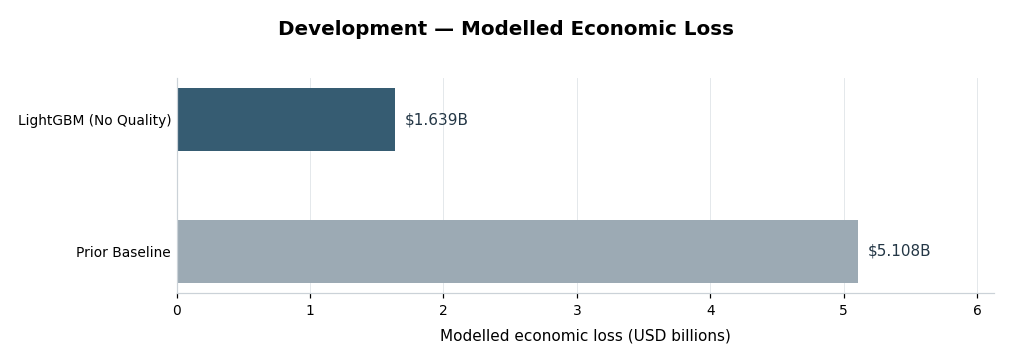

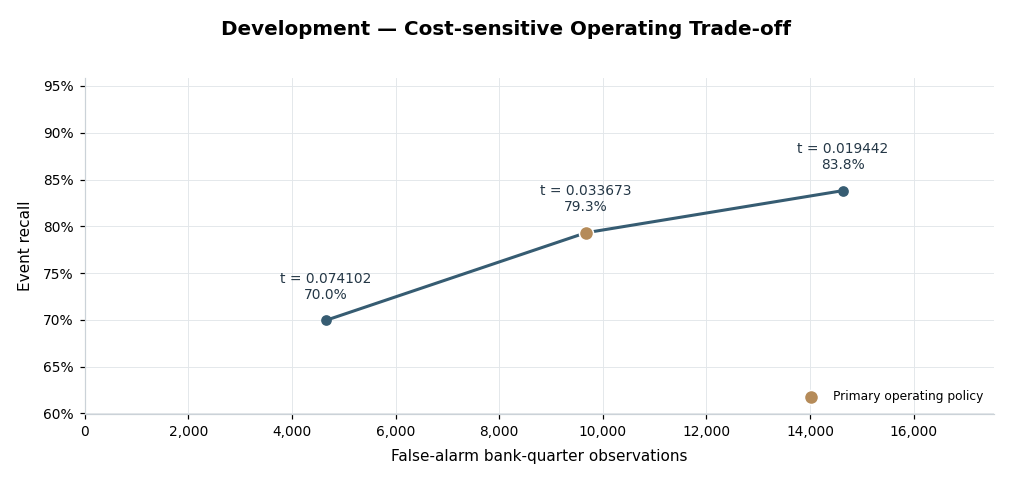

*Note: Missed failures are charged once per distinct represented failure event. Thresholds are optimized exclusively on development OOF predictions. A threshold above 1 denotes the no-alarm policy. Economic losses are scenario-based estimates, not realized monetary savings.*

In [ ]:
import json


# ============================================================
# Table 6. Economic proxy provenance
# ============================================================

cost = json.loads(
    (EVIDENCE / "cost_policy.json").read_text()
)

COST_LABELS = {
    "c_fn": "Missed-event cost",
    "c_fp": "False-alarm cost",
    "conflicting_dated_cost_events":
        "Conflicting dated cost events",
    "cutoff": "Historical cost cutoff",
    "eligible_dated_cost_events":
        "Eligible dated FDIC cost events",
    "excluded_cost_records_by_vintage":
        "Cost records excluded by vintage",
    "fallback_loss_fraction":
        "Assumed failed-bank asset loss fraction",
    "median_development_assets":
        "Median development assets",
    "median_eligible_fdic_cost":
        "Median eligible FDIC resolution cost",
    "median_failed_event_assets":
        "Median failed-event assets",
    "minimum_dated_cost_events":
        "Minimum eligible cost events required",
    "missed_cost_source":
        "Missed-event cost source",
    "positive_current_cost_events":
        "Events with positive current COST",
    "represented_development_events":
        "Represented development failure events",
    "review_asset_fraction":
        "Assumed review-cost asset fraction",
    "unit": "Monetary unit"
}

COST_SOURCE_LABELS = {
    "assumed_10pct_of_median_failed_bank_assets":
        "10% of median failed-bank assets (assumed)"
}

MONEY_FIELDS = {
    "c_fn",
    "c_fp",
    "median_development_assets",
    "median_eligible_fdic_cost",
    "median_failed_event_assets"
}

PERCENT_FIELDS = {
    "fallback_loss_fraction",
    "review_asset_fraction"
}


def format_cost_value(key, value):

    if value is None:
        return "—"

    if key in MONEY_FIELDS:
        return f"{value:,.3f}"

    if key in PERCENT_FIELDS:
        return f"{value:.2%}"

    if key == "missed_cost_source":
        return COST_SOURCE_LABELS.get(
            value,
            str(value)
        )

    if isinstance(value, bool):
        return "Yes" if value else "No"

    if isinstance(value, int):
        return f"{value:,}"

    if isinstance(value, float):
        return f"{value:,.6f}"

    return str(value)


cost_order = [
    "cutoff",
    "represented_development_events",
    "positive_current_cost_events",
    "eligible_dated_cost_events",
    "excluded_cost_records_by_vintage",
    "conflicting_dated_cost_events",
    "minimum_dated_cost_events",
    "median_eligible_fdic_cost",
    "missed_cost_source",
    "median_development_assets",
    "median_failed_event_assets",
    "review_asset_fraction",
    "fallback_loss_fraction",
    "c_fp",
    "c_fn",
    "unit"
]

cost_order = [
    key for key in cost_order
    if key in cost
] + [
    key for key in cost
    if key not in cost_order
]

cost_display = pd.DataFrame([
    {
        "Diagnostic": COST_LABELS.get(key, key),
        "Value": format_cost_value(key, cost[key])
    }
    for key in cost_order
])

display_table(
    cost_display,
    "Table 6. Economic proxy provenance"
)

spacer(12)

display(Markdown(
    "*Note: Monetary amounts are expressed in nominal "
    "USD thousands. Asset-scaled costs are modelling "
    "assumptions rather than observed supervisory "
    "expenses or realized intervention savings.*"
))


# ============================================================
# Table 7. OOF threshold sensitivity
# ============================================================

sensitivity = pd.read_csv(
    EVIDENCE / "threshold_sensitivity.csv"
)

display_table(
    sensitivity[[
        "model",
        "scenario",
        "c_fp",
        "c_fn",
        "threshold",
        "fp",
        "missed_events",
        "detected_events",
        "event_recall",
        "loss_usd_thousands"
    ]],
    "Table 7. OOF threshold sensitivity",
    labels={
        "model": "Model",
        "scenario": "Cost scenario",
        "c_fp": "C_FP",
        "c_fn": "C_FN",
        "threshold": "Threshold",
        "fp": "False alarms",
        "missed_events": "Missed",
        "detected_events": "Detected",
        "event_recall": "Event recall",
        "loss_usd_thousands":
            "Modelled loss (USD thousands)"
    },
    formats={
        "c_fp": "{:,.3f}",
        "c_fn": "{:,.3f}",
        "threshold": "{:.6f}",
        "fp": "{:,.0f}",
        "missed_events": "{:,.0f}",
        "detected_events": "{:,.0f}",
        "event_recall": "{:.2%}",
        "loss_usd_thousands": "{:,.2f}"
    }
)


# ============================================================
# Load locked operating policies
# ============================================================

operating = pd.read_csv(
    EVIDENCE / "development_operating.csv"
)


# ============================================================
# Table 8a. Bank-quarter operating performance
# ============================================================

display_table(
    operating[[
        "model",
        "threshold",
        "tp",
        "fp",
        "fn",
        "tn",
        "alerts",
        "alert_rate",
        "precision",
        "recall",
        "fpr"
    ]],
    "Table 8a. Locked bank-quarter operating policies",
    labels={
        "model": "Model",
        "threshold": "Threshold",
        "tp": "TP",
        "fp": "FP",
        "fn": "FN",
        "tn": "TN",
        "alerts": "Alarms",
        "alert_rate": "Alert rate",
        "precision": "Precision",
        "recall": "Recall",
        "fpr": "False-positive rate"
    },
    formats={
        "threshold": "{:.6f}",
        **{
            c: "{:,.0f}"
            for c in [
                "tp", "fp", "fn", "tn", "alerts"
            ]
        },
        **{
            c: "{:.2%}"
            for c in [
                "alert_rate", "precision", "recall", "fpr"
            ]
        }
    }
)


# ============================================================
# Table 8b. Event-level operating performance
# ============================================================

display_table(
    operating[[
        "model",
        "events",
        "detected_events",
        "missed_events",
        "event_recall",
        "median_lead_days",
        "lead_at_least_90_days",
        "loss_usd_thousands"
    ]],
    "Table 8b. Locked event-level operating policies",
    labels={
        "model": "Model",
        "events": "Failure events",
        "detected_events": "Detected",
        "missed_events": "Missed",
        "event_recall": "Event recall",
        "median_lead_days": "Median lead time (days)",
        "lead_at_least_90_days": "Lead time ≥ 90 days",
        "loss_usd_thousands":
            "Modelled loss (USD thousands)"
    },
    formats={
        **{
            c: "{:,.0f}"
            for c in [
                "events",
                "detected_events",
                "missed_events",
                "lead_at_least_90_days"
            ]
        },
        "event_recall": "{:.2%}",
        "median_lead_days": "{:.1f}",
        "loss_usd_thousands": "{:,.2f}"
    }
)


# ============================================================
# Frozen thresholds
# ============================================================

threshold_display = pd.DataFrame([
    {
        "Model": MODEL_LABELS.get(name, name),
        "Frozen threshold": str(value),
        "Operating policy":
            "No alarm" if value > 1
            else "Score ≥ threshold"
    }
    for name, value in S["thresholds"].items()
])

display_table(
    threshold_display,
    "Locked thresholds — full recorded precision"
)


# ============================================================
# Figure 5. Economic loss comparison
# ============================================================

loss_plot = operating.copy()

loss_plot["loss_usd_billions"] = (
    loss_plot.loss_usd_thousands / 1_000_000
)

loss_plot = loss_plot.sort_values(
    "loss_usd_billions",
    ascending=False
)

fig, ax = plt.subplots(
    figsize=(9.2, 3.3),
    layout="constrained"
)

bars = ax.barh(
    loss_plot.model.map(MODEL_LABELS),
    loss_plot.loss_usd_billions,
    color=[
        PRIMARY if name == SELECTED else SECONDARY
        for name in loss_plot.model
    ],
    height=0.48
)

ax.bar_label(
    bars,
    labels=[
        f"${value:.3f}B"
        for value in loss_plot.loss_usd_billions
    ],
    padding=6,
    fontsize=10,
    color=TEXT
)

ax.set(
    xlabel="Modelled economic loss (USD billions)",
    xlim=(
        0,
        max(loss_plot.loss_usd_billions.max(), 0.01)
        * 1.20
    )
)

ax.grid(
    axis="x",
    color=GRID,
    linewidth=0.6
)

ax.set_axisbelow(True)
ax.tick_params(axis="y", length=0)

show_figure(
    fig,
    "Development — Modelled Economic Loss",
    width=850
)


# ============================================================
# Figure 6. Cost-sensitive operating trade-off
# ============================================================

tradeoff = sensitivity.loc[
    sensitivity.model.eq(SELECTED)
].copy()

tradeoff = (
    tradeoff
    .groupby(
        ["fp", "event_recall", "threshold"],
        as_index=False
    )
    .agg({
        "scenario": lambda x: " / ".join(x)
    })
    .sort_values("fp")
)

primary_policy = sensitivity.loc[
    sensitivity.model.eq(SELECTED)
    & sensitivity.scenario.eq("primary")
].iloc[0]

fig, ax = plt.subplots(
    figsize=(9.2, 4.4),
    layout="constrained"
)

ax.plot(
    tradeoff.fp,
    tradeoff.event_recall,
    color=PRIMARY,
    marker="o",
    markersize=6,
    linewidth=2
)

ax.scatter(
    primary_policy.fp,
    primary_policy.event_recall,
    s=85,
    color=ACCENT,
    edgecolor="white",
    linewidth=1,
    zorder=5,
    label="Primary operating policy"
)

for row in tradeoff.itertuples():

    ax.annotate(
        f"t = {row.threshold:.6f}\n"
        f"{row.event_recall:.1%}",
        xy=(row.fp, row.event_recall),
        xytext=(0, 12),
        textcoords="offset points",
        ha="center",
        va="bottom",
        fontsize=9,
        color=TEXT
    )

ax.set(
    xlabel="False-alarm bank-quarter observations",
    ylabel="Event recall"
)

xmax = max(
    float(tradeoff.fp.max()),
    1.0
)

ax.set_xlim(0, xmax * 1.2)

ymin = max(
    0,
    float(tradeoff.event_recall.min()) - 0.10
)

ymax = min(
    1.05,
    float(tradeoff.event_recall.max()) + 0.12
)

ax.set_ylim(ymin, ymax)

ax.xaxis.set_major_formatter(
    mtick.StrMethodFormatter("{x:,.0f}")
)

ax.yaxis.set_major_formatter(
    mtick.PercentFormatter(
        xmax=1,
        decimals=0
    )
)

ax.grid(
    color=GRID,
    linewidth=0.6
)

ax.set_axisbelow(True)
ax.legend(loc="lower right")

show_figure(
    fig,
    "Development — Cost-sensitive Operating Trade-off",
    width=850
)

display(Markdown(
    "*Note: Missed failures are charged once per "
    "distinct represented failure event. Thresholds "
    "are optimized exclusively on development OOF "
    "predictions. A threshold above 1 denotes the "
    "no-alarm policy. Economic losses are scenario-based "
    "estimates, not realized monetary savings.*"
))

spacer(20)


## 9. Native Spark MLlib demonstration
Fit a Spark pipeline on a sampled training population from the first fold; evaluate all labelled first-fold validation observations at natural prevalence. Sampling is training-only. This demonstration does not participate in model selection.

**Table 9a. Spark MLlib experimental design**

Diagnostic,Value
Spark version,4.0.1
Execution mode,local[2]
Raw predictors,5
Training population,"258,180"
Sampled training observations,"22,536"
Sampled training negatives,"20,000"
Training positives retained,"2,536"
Validation observations,"233,498"
Validation positives,"3,864"
Validation prevalence,1.6548%


**Spark MLlib predictor specification**

Predictor
LOG_ASSET
EQUITY_ASSETS_PCT
DEPOSITS_ASSETS_PCT
LOANS_ASSETS_PCT
ROA_PCT


**Table 9b. Spark MLlib development performance**

Metric,Value
Average Precision,0.271067
ROC-AUC,0.866379
Brier score,0.019347
Log loss,0.117826
Quarterly top-5% recall,59.45%
Model fit time,19.76 s
Validation scoring time,12.20 s


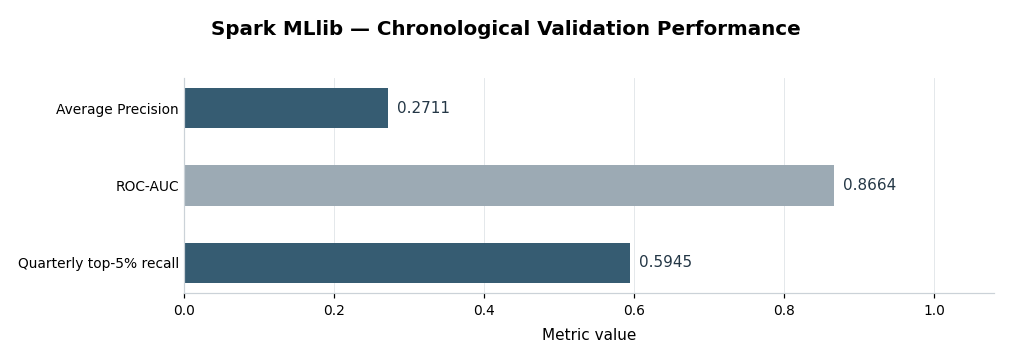

*Note: Negative observations are subsampled only within the first-fold training population. All eligible first-fold validation observations are retained at natural prevalence. The Spark experiment demonstrates native distributed ML pipeline functionality in local execution mode and does not participate in primary model selection.*

In [15]:
# ============================================================
# Load verified Spark evidence
# ============================================================

spark = json.loads(
    (EVIDENCE / "spark_demo.json").read_text()
)

assert not spark["validation_sampled"]


# ============================================================
# Table 9a. Spark experimental design
# ============================================================

spark_design = pd.DataFrame([
    {
        "Diagnostic": "Spark version",
        "Value": str(spark["spark_version"])
    },
    {
        "Diagnostic": "Execution mode",
        "Value": spark["mode"]
    },
    {
        "Diagnostic": "Raw predictors",
        "Value": f"{len(spark['features']):,}"
    },
    {
        "Diagnostic": "Training population",
        "Value": f"{spark['training_population_rows']:,}"
    },
    {
        "Diagnostic": "Sampled training observations",
        "Value": f"{spark['sampled_training_rows']:,}"
    },
    {
        "Diagnostic": "Sampled training negatives",
        "Value": f"{spark['sampled_negative_rows']:,}"
    },
    {
        "Diagnostic": "Training positives retained",
        "Value": f"{spark['sampled_positive_rows']:,}"
    },
    {
        "Diagnostic": "Validation observations",
        "Value": f"{spark['rows']:,}"
    },
    {
        "Diagnostic": "Validation positives",
        "Value": f"{spark['positives']:,}"
    },
    {
        "Diagnostic": "Validation prevalence",
        "Value": f"{spark['prevalence']:.4%}"
    },
    {
        "Diagnostic": "Validation sampled",
        "Value": (
            "Yes" if spark["validation_sampled"]
            else "No — full population"
        )
    }
])

display_table(
    spark_design,
    "Table 9a. Spark MLlib experimental design"
)


# ============================================================
# Spark feature specification
# ============================================================

spark_features = pd.DataFrame({
    "Predictor": spark["features"]
})

display_table(
    spark_features,
    "Spark MLlib predictor specification"
)


# ============================================================
# Table 9b. Predictive and computational diagnostics
# ============================================================

spark_performance = pd.DataFrame([
    {
        "Metric": "Average Precision",
        "Value": f"{spark['ap']:.6f}"
    },
    {
        "Metric": "ROC-AUC",
        "Value": f"{spark['roc_auc']:.6f}"
    },
    {
        "Metric": "Brier score",
        "Value": f"{spark['brier']:.6f}"
    },
    {
        "Metric": "Log loss",
        "Value": f"{spark['log_loss']:.6f}"
    },
    {
        "Metric": "Quarterly top-5% recall",
        "Value": (
            f"{spark['recall_top5pct_by_quarter']:.2%}"
        )
    },
    {
        "Metric": "Model fit time",
        "Value": f"{spark['fit_seconds']:,.2f} s"
    },
    {
        "Metric": "Validation scoring time",
        "Value": f"{spark['score_seconds']:,.2f} s"
    }
])

display_table(
    spark_performance,
    "Table 9b. Spark MLlib development performance"
)


# ============================================================
# Figure 7. Spark predictive performance
# ============================================================

spark_plot = pd.DataFrame({
    "Metric": [
        "Average Precision",
        "ROC-AUC",
        "Quarterly top-5% recall"
    ],
    "Value": [
        spark["ap"],
        spark["roc_auc"],
        spark["recall_top5pct_by_quarter"]
    ]
})

spark_plot = spark_plot.iloc[::-1]

fig, ax = plt.subplots(
    figsize=(9.2, 3.3),
    layout="constrained"
)

bars = ax.barh(
    spark_plot.Metric,
    spark_plot.Value,
    color=[
        PRIMARY,
        SECONDARY,
        PRIMARY
    ],
    height=0.52
)

ax.bar_label(
    bars,
    fmt="%.4f",
    padding=6,
    fontsize=10,
    color=TEXT
)

ax.set(
    xlabel="Metric value",
    xlim=(0, 1.08)
)

ax.grid(
    axis="x",
    color=GRID,
    linewidth=0.6
)

ax.set_axisbelow(True)
ax.tick_params(axis="y", length=0)

show_figure(
    fig,
    "Spark MLlib — Chronological Validation Performance",
    width=850
)

display(Markdown(
    "*Note: Negative observations are subsampled only "
    "within the first-fold training population. "
    "All eligible first-fold validation observations "
    "are retained at natural prevalence. The Spark "
    "experiment demonstrates native distributed ML "
    "pipeline functionality in local execution mode "
    "and does not participate in primary model selection.*"
))

spacer(20)


## 10. Sealed development handoff
Confirm that model, features, costs, cutoff and environment are sealed before opening Notebook 07. Save this notebook with its outputs. Do not modify development evidence after sealing.

In [ ]:
print('Selected specification:',SELECTED)
print('Final fit:',json.dumps(json.loads((EVIDENCE/'final_fit.json').read_text()),indent=2))
print('Runtime:',json.dumps(DM['environment'],indent=2))
print('Development observations:',S['development_rows'])
print('Development seal:',sha256(EVIDENCE/'development_manifest.json'))
print('Workspace test attempt already exists:',ATTEMPT.exists())
print('Next: Notebook 07 — Historical Test and Evaluation')

Selected specification: lightgbm_no_quality
Final fit: {
  "capital_zero_as_missing": false,
  "features": [
    "LOG_ASSET",
    "EQUITY_ASSETS_PCT",
    "TANGIBLE_EQUITY_ASSETS_PCT",
    "DEPOSITS_ASSETS_PCT",
    "CASH_ASSETS_PCT",
    "SECURITIES_ASSETS_PCT",
    "LOANS_ASSETS_PCT",
    "BROKERED_DEPOSITS_PCT",
    "LOANS_DEPOSITS_PCT",
    "NONCURRENT_LOANS_PCT",
    "ALLOWANCE_LOANS_PCT",
    "TEXAS_LIKE_PCT",
    "ROA_PCT",
    "ROE_PCT",
    "NIM_PCT",
    "RBC1AAJ_REPORTED_PCT",
    "RBCRWAJ_REPORTED_PCT",
    "ASSET_GROWTH_QOQ_PCT",
    "DEPOSIT_GROWTH_QOQ_PCT",
    "ASSET_GROWTH_YOY_PCT",
    "ROA_CHANGE_YOY_PPT",
    "ROA_PEER_DEV_PPT"
  ],
  "first_decision": "1984-06-30",
  "fit_rows": 1082584,
  "fit_seconds": 30.259582093000063,
  "last_decision": "2006-12-31"
}
Runtime: {
  "joblib": "1.5.2",
  "lightgbm": "4.6.0",
  "numpy": "2.2.6",
  "pandas": "2.2.3",
  "pyarrow": "21.0.0",
  "pyspark": "4.0.1",
  "python": "3.13.18",
  "scikit-learn": "1.7.2"
}
Development observa